### Начнём с того, что подтащим датасет из kagle

In [4]:
from pathlib import Path

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
SLUG = "antonkozyriev/game-recommendations-on-steam"
NEED = ["recommendations.csv", "games.csv", "users.csv", "games_metadata.json"]

missing = [f for f in NEED if not (DATA_DIR / f).exists()]
print("Не хватает:", missing)

Не хватает: []


Качаем недостающее

In [5]:
if missing:
    import subprocess, sys
    subprocess.run(
        ["kaggle", "datasets", "download", "-d", SLUG,
         "-p", str(DATA_DIR), "--unzip"],
        check=True,
    )
print(sorted(p.name for p in DATA_DIR.iterdir()))

['games.csv', 'games_metadata.json', 'recommendations.csv', 'users.csv']


### Смотрим на колонки


In [6]:
import pandas as pd
print(pd.read_csv(DATA_DIR / "recommendations.csv", nrows=5))
print(pd.read_csv(DATA_DIR / "games.csv", nrows=5).columns.tolist())

    app_id  helpful  funny        date  is_recommended  hours  user_id  \
0   975370        0      0  2022-12-12            True   36.3    51580   
1   304390        4      0  2017-02-17           False   11.5     2586   
2  1085660        2      0  2019-11-17            True  336.5   253880   
3   703080        0      0  2022-09-23            True   27.4   259432   
4   526870        0      0  2021-01-10            True    7.9    23869   

   review_id  
0          0  
1          1  
2          2  
3          3  
4          4  
['app_id', 'title', 'date_release', 'win', 'mac', 'linux', 'rating', 'positive_ratio', 'user_reviews', 'price_final', 'price_original', 'discount', 'steam_deck']


### Делаем подвыборку

In [7]:
SEED = 115200
REC = DATA_DIR / "recommendations.csv"
CHUNK = 5_000_000

counts = pd.Series(dtype="int64")
n_raw = 0
for ch in pd.read_csv(REC, usecols=["user_id"], dtype={"user_id": "int32"}, chunksize=CHUNK):
    n_raw += len(ch)
    counts = counts.add(ch["user_id"].value_counts(), fill_value=0)
counts = counts.astype("int64")
print("строк в исходном файле:", n_raw)
print("пользователей:", len(counts))
print(counts.describe())

строк в исходном файле: 41154794
пользователей: 13781059
count    1.378106e+07
mean     2.986330e+00
std      8.118011e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      3.000000e+00
max      6.045000e+03
dtype: float64


In [8]:
import numpy as np
MIN_U = 5
N_USERS = 100_000

eligible = counts[counts >= MIN_U].index.to_numpy()
rng = np.random.default_rng(SEED)
users_sel = rng.choice(eligible, size=min(N_USERS, len(eligible)), replace=False)
users_set = set(users_sel.tolist())
print("подходящих пользователей:", len(eligible), "выбрано:", len(users_sel))

подходящих пользователей: 1910831 выбрано: 100000


### Достаём их отзывы

In [9]:
parts = []
dtypes = {"app_id": "int32", "user_id": "int32", "hours": "float32", "is_recommended": "bool"}
cols = ["app_id", "user_id", "date", "is_recommended", "hours"]
for ch in pd.read_csv(REC, usecols=cols, dtype=dtypes, chunksize=CHUNK):
    parts.append(ch[ch["user_id"].isin(users_set)])
df = pd.concat(parts, ignore_index=True)
df["date"] = pd.to_datetime(df["date"])
print("после выбора пользователей:", len(df))

# дубликаты (user, game): оставляем последний по дате
n0 = len(df)
df = df.sort_values("date").drop_duplicates(["user_id", "app_id"], keep="last").reset_index(drop=True)
print("дубликатов удалено:", n0 - len(df), "-> строк:", len(df))
print(df.isna().sum())

после выбора пользователей: 1173335
дубликатов удалено: 0 -> строк: 1173335
app_id            0
date              0
is_recommended    0
hours             0
user_id           0
dtype: int64


### Уменьшаем выборку игр

In [10]:
games = pd.read_csv(DATA_DIR / "games.csv")
print("игр в games.csv:", len(games), "| дубликатов app_id:", games["app_id"].duplicated().sum())

n0 = len(df)
df = df[df["app_id"].isin(games["app_id"])]
print("после фильтра по games.csv:", n0, "->", len(df))

TOP_ITEMS = 5000
top_apps = df["app_id"].value_counts().head(TOP_ITEMS).index
df = df[df["app_id"].isin(top_apps)]
print(f"после топ-{TOP_ITEMS} игр:", len(df))

игр в games.csv: 50872 | дубликатов app_id: 0
после фильтра по games.csv: 1173335 -> 1173335
после топ-5000 игр: 1073884


In [11]:
MIN_U, MIN_I = 5, 20

def kcore(d, min_u, min_i):
    while True:
        n = len(d)
        d = d[d.groupby("user_id")["user_id"].transform("size") >= min_u]
        d = d[d.groupby("app_id")["app_id"].transform("size") >= min_i]
        if len(d) == n:
            return d

df = kcore(df, MIN_U, MIN_I)
print("после k-core:", len(df),
      "| пользователей:", df["user_id"].nunique(),
      "| игр:", df["app_id"].nunique())

после k-core: 1054338 | пользователей: 94688 | игр: 4995


In [12]:
df = df.sort_values("date").reset_index(drop=True)

uid_codes, uid_uniques = pd.factorize(df["user_id"])
iid_codes, iid_uniques = pd.factorize(df["app_id"])
df["u"] = uid_codes.astype("int32")
df["i"] = iid_codes.astype("int32")

n_users, n_items = len(uid_uniques), len(iid_uniques)
print("взаимодействий:", len(df), "| пользователей:", n_users, "| игр:", n_items)
print("разреженность:", 1 - len(df) / (n_users * n_items))
print("доля is_recommended:", df["is_recommended"].mean())
print("период:", df["date"].min(), "->", df["date"].max())

# таблица соответствий пригодится для метаданных игр
item_map = pd.DataFrame({"i": np.arange(n_items), "app_id": iid_uniques})

взаимодействий: 1054338 | пользователей: 94688 | игр: 4995
разреженность: 0.9977707980031401
доля is_recommended: 0.8561969690934027
период: 2010-10-15 00:00:00 -> 2022-12-31 00:00:00


### Проверим на пропуски и дубликаты

In [13]:
import matplotlib.pyplot as plt

print(df.dtypes)
print("пропуски:\n", df[["u", "i", "date", "is_recommended", "hours"]].isna().sum())
print("дубликатов (u, i):", df.duplicated(["u", "i"]).sum())
print(df["hours"].describe())
print("hours == 0:", (df["hours"] == 0).mean())

app_id                     int32
date              datetime64[us]
is_recommended              bool
hours                    float32
user_id                    int32
u                          int32
i                          int32
dtype: object
пропуски:
 u                 0
i                 0
date              0
is_recommended    0
hours             0
dtype: int64
дубликатов (u, i): 0
count    1.054338e+06
mean     8.084452e+01
std      1.517097e+02
min      0.000000e+00
25%      7.000000e+00
50%      2.240000e+01
75%      7.430000e+01
max      9.999000e+02
Name: hours, dtype: float64
hours == 0: 0.0036525288854238392


### EDA

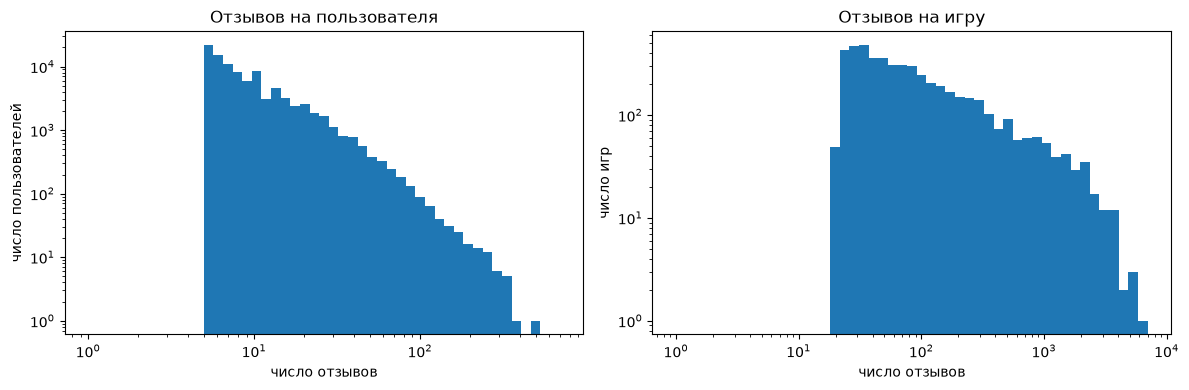

count    94688.000000
mean        11.134864
std         12.660251
min          5.000000
25%          6.000000
50%          7.000000
75%         12.000000
max        695.000000
dtype: float64
count    4995.000000
mean      211.078679
std       455.368417
min        20.000000
25%        35.000000
50%        65.000000
75%       164.500000
max      6989.000000
dtype: float64
доля взаимодействий на топ-1% игр: 0.156


In [11]:
u_cnt = df.groupby("u").size()
i_cnt = df.groupby("i").size()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(u_cnt, bins=np.logspace(0, np.log10(u_cnt.max()), 50))
ax[0].set(xscale="log", yscale="log", title="Отзывов на пользователя",
          xlabel="число отзывов", ylabel="число пользователей")
ax[1].hist(i_cnt, bins=np.logspace(0, np.log10(i_cnt.max()), 50))
ax[1].set(xscale="log", yscale="log", title="Отзывов на игру",
          xlabel="число отзывов", ylabel="число игр")
plt.tight_layout(); plt.show()

print(u_cnt.describe()); print(i_cnt.describe())
# доля взаимодействий, приходящаяся на топ-1% игр
top1 = i_cnt.sort_values(ascending=False).head(max(1, n_items // 100)).sum() / len(df)
print("доля взаимодействий на топ-1% игр:", round(top1, 3))

In [12]:
sparsity = 1 - len(df) / (n_users * n_items)
print(f"разреженность: {sparsity:.5f}")
print("доля is_recommended:", df["is_recommended"].mean())

разреженность: 0.99777
доля is_recommended: 0.8561969690934027


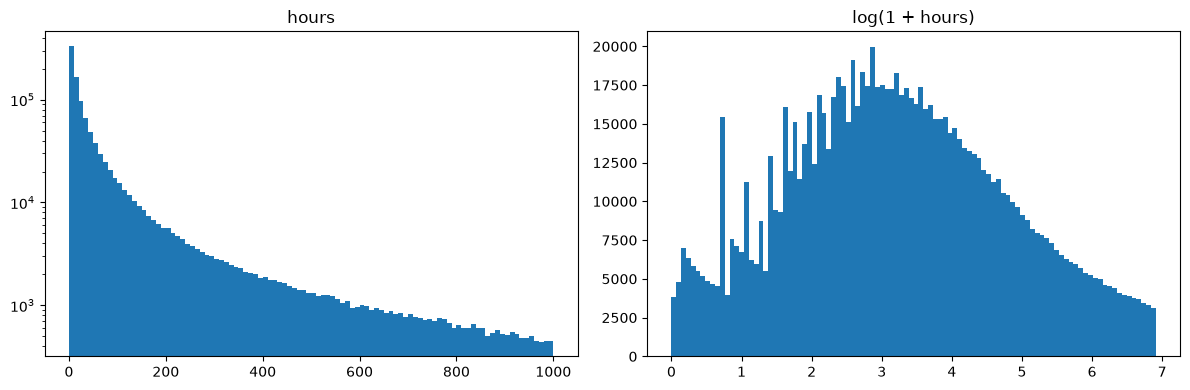

is_recommended
False    10.000000
True     24.799999
Name: hours, dtype: float32


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df["hours"], bins=100); ax[0].set(title="hours", yscale="log")
ax[1].hist(np.log1p(df["hours"]), bins=100); ax[1].set(title="log(1 + hours)")
plt.tight_layout(); plt.show()

print(df.groupby("is_recommended")["hours"].median())

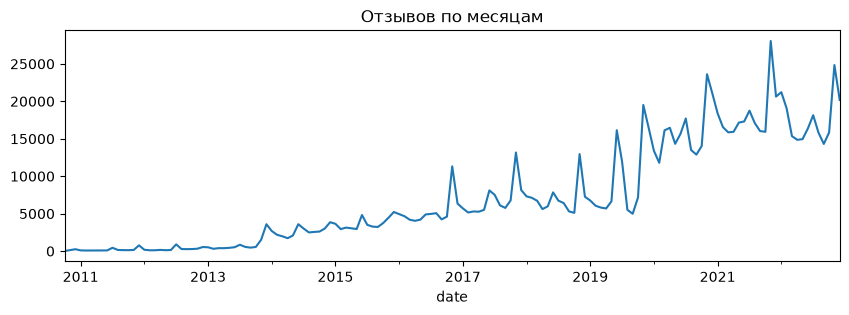

0.7 2021-07-17
0.8 2022-01-01
0.9 2022-07-06


In [14]:
monthly = df.set_index("date").resample("MS").size()
monthly.plot(figsize=(10, 3), title="Отзывов по месяцам")
plt.show()

for q in [0.7, 0.8, 0.9]:
    print(q, df["date"].quantile(q).date())

        price_final         rating   win    mac  linux steam_deck
count   4995.000000           4995  4995   4995   4995       4995
unique          NaN              7     2      2      2          2
top             NaN  Very Positive  True  False  False       True
freq            NaN           2823  4991   3171   3713       4994
mean      14.273365            NaN   NaN    NaN    NaN        NaN
std       13.450658            NaN   NaN    NaN    NaN        NaN
min        0.000000            NaN   NaN    NaN    NaN        NaN
25%        2.990000            NaN   NaN    NaN    NaN        NaN
50%       10.990000            NaN   NaN    NaN    NaN        NaN
75%       19.990000            NaN   NaN    NaN    NaN        NaN
max      149.000000            NaN   NaN    NaN    NaN        NaN
rating
Very Positive              2823
Mostly Positive             788
Overwhelmingly Positive     769
Mixed                       573
Mostly Negative              34
Overwhelmingly Negative       4
Positive 

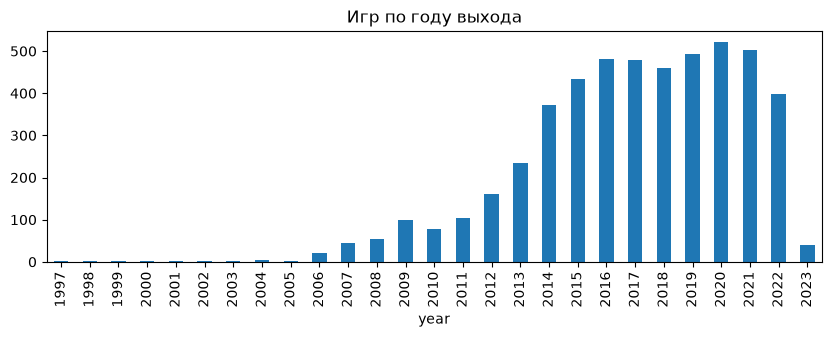

In [15]:
g = games.merge(item_map, on="app_id")  # только игры, попавшие в датасет
g["year"] = pd.to_datetime(g["date_release"]).dt.year

print(g[["price_final", "rating", "win", "mac", "linux", "steam_deck"]].describe(include="all"))
print(g["rating"].value_counts())
g["year"].value_counts().sort_index().plot(kind="bar", figsize=(10, 3), title="Игр по году выхода")
plt.show()

### Разбиение выборки

In [14]:
import scipy.sparse as sp

T_VAL  = pd.Timestamp("2022-01-01")
T_TEST = pd.Timestamp("2022-07-01")

tr = df[df["date"] <  T_VAL]
va = df[(df["date"] >= T_VAL) & (df["date"] < T_TEST)]
te = df[df["date"] >= T_TEST]
for name, d in [("train", tr), ("val", va), ("test", te)]:
    print(name, len(d), f"{len(d)/len(df):.3f}", "| доля положительных:", round(d["is_recommended"].mean(), 3))

shape = (n_users, n_items)

def to_csr(d):
    return sp.csr_matrix((np.ones(len(d), dtype=np.float32), (d["u"].values, d["i"].values)), shape=shape)

def eval_setup(seen_df, target_df):
    seen = to_csr(seen_df)                                   # что пользователь уже видел
    cand = np.asarray(seen.sum(0)).ravel() > 0               # игры, известные на момент рекомендации
    Y = to_csr(target_df[target_df["is_recommended"]])       # релевантные в целевом периоде
    n_rel_all = Y.nnz
    Y = (Y @ sp.diags(cand.astype(np.float32))).tocsr()      # отбрасываем холодные игры
    Y.eliminate_zeros()
    has_hist = np.asarray(seen.sum(1)).ravel() > 0
    has_rel  = np.asarray(Y.sum(1)).ravel() > 0
    users = np.where(has_hist & has_rel)[0]
    print(f"оцениваемых пользователей: {len(users)} | релевантных пар: {Y.nnz} из {n_rel_all} "
          f"| в среднем на пользователя: {Y[users].sum(1).mean():.2f} | игр-кандидатов: {cand.sum()}")
    return seen, Y, cand, users

print("VAL:");  X_seen_val,  Y_val,  cand_val,  users_val  = eval_setup(tr, va)
trva = pd.concat([tr, va])
print("TEST:"); X_seen_test, Y_test, cand_test, users_test = eval_setup(trva, te)

train 843414 0.800 | доля положительных: 0.858
val 101803 0.097 | доля положительных: 0.852
test 109121 0.103 | доля положительных: 0.844
VAL:
оцениваемых пользователей: 30908 | релевантных пар: 74062 из 86754 | в среднем на пользователя: 2.17 | игр-кандидатов: 4674
TEST:
оцениваемых пользователей: 32816 | релевантных пар: 74550 из 92056 | в среднем на пользователя: 2.13 | игр-кандидатов: 4828


Общая функция, чтобы сравнивать модели

In [24]:
def evaluate(model, X_seen, Y_rel, cand, users, K=10, bs=2048):
    disc = 1.0 / np.log2(np.arange(2, K + 2))     # веса позиций 1..K
    ideal = np.cumsum(disc)                        # IDCG для 1..K релевантных
    ndcg, recall, shown = [], [], set()

    for s in range(0, len(users), bs):
        u = users[s:s + bs]
        S = np.asarray(model.score(u), dtype=np.float32)

        S[:, ~cand] = -np.inf                      # не кандидаты
        seen = X_seen[u].tocoo()
        S[seen.row, seen.col] = -np.inf            # уже виденные

        top = np.argpartition(-S, K, axis=1)[:, :K]            # K лучших (неупорядоченно)
        order = np.argsort(-np.take_along_axis(S, top, 1), axis=1)
        top = np.take_along_axis(top, order, 1)                # упорядоченные по скору

        rel = Y_rel[u].toarray() > 0
        hit = np.take_along_axis(rel, top, 1)                  # попали ли в релевантные
        n_rel = rel.sum(1)

        ndcg.append((hit * disc).sum(1) / ideal[np.minimum(n_rel, K) - 1])
        recall.append(hit.sum(1) / n_rel)
        shown.update(top.ravel().tolist())

    return {"NDCG@10": float(np.concatenate(ndcg).mean()),
            "Recall@10": float(np.concatenate(recall).mean()),
            "Coverage@10": len(shown) / int(cand.sum())}

In [18]:
class RandomModel:
    def __init__(self, n_items, seed=42):
        self.n = n_items; self.rng = np.random.default_rng(seed)
    def score(self, users):
        return self.rng.random((len(users), self.n), dtype=np.float32)

class PopularityModel:
    def fit(self, X_train):
        self.pop = np.asarray(X_train.sum(0)).ravel().astype(np.float32)
        return self
    def score(self, users):
        return np.tile(self.pop, (len(users), 1))

rand = RandomModel(n_items)
pop  = PopularityModel().fit(X_seen_val)     # популярность считаем по train

print("Random VAL:", evaluate(rand, X_seen_val, Y_val, cand_val, users_val))
print("Popularity VAL:", evaluate(pop, X_seen_val, Y_val, cand_val, users_val))

Random VAL: {'NDCG@10': 0.0011477871250996096, 'Recall@10': 0.002122599582405895, 'Coverage@10': 1.0}
Popularity VAL: {'NDCG@10': 0.020229839263289518, 'Recall@10': 0.03323701985907561, 'Coverage@10': 0.006632434745400086}


EASE

In [2]:
from models.ease import EASE

import time
for lam in [100, 500, 2000, 10000]:
    t = time.time()
    m = EASE(lam).fit(X_seen_val)
    r = evaluate(m, X_seen_val, Y_val, cand_val, users_val)
    print(f"lam={lam:>6}  {r}  ({time.time()-t:.0f} с)")

NameError: name 'X_seen_val' is not defined

Возмём больше так как быстро отработали

In [20]:
res = []
for lam in [1, 3, 10, 30, 100, 300]:
    m = EASE(lam).fit(X_seen_val)
    r = evaluate(m, X_seen_val, Y_val, cand_val, users_val)
    res.append({"lam": lam, **r})
    print(f"lam={lam:>5}  NDCG={r['NDCG@10']:.4f}  Recall={r['Recall@10']:.4f}  Cov={r['Coverage@10']:.3f}")

lam=    1  NDCG=0.0571  Recall=0.0920  Cov=0.650
lam=    3  NDCG=0.0574  Recall=0.0929  Cov=0.641
lam=   10  NDCG=0.0584  Recall=0.0946  Cov=0.614
lam=   30  NDCG=0.0596  Recall=0.0966  Cov=0.560
lam=  100  NDCG=0.0602  Recall=0.0986  Cov=0.485
lam=  300  NDCG=0.0593  Recall=0.0978  Cov=0.423


пространство поиска λ ∈ {1, 3, 10, 30, 100, 300, 1000, 2000, 10000} (объединение двух прогонов), лучшее λ=100,

## KNN

In [22]:
from models.knn import ItemKNN

for k in [20, 50, 100, 300]:
    for beta in [0, 10, 50]:
        t = time.time()
        m = ItemKNN(k, beta).fit(X_seen_val)
        r = evaluate(m, X_seen_val, Y_val, cand_val, users_val)
        print(f"k={k:>3} beta={beta:>3}  NDCG={r['NDCG@10']:.4f}  Recall={r['Recall@10']:.4f}  Cov={r['Coverage@10']:.3f}  ({time.time()-t:.0f} с)")

k= 20 beta=  0  NDCG=0.0503  Recall=0.0802  Cov=0.938  (2 с)
k= 20 beta= 10  NDCG=0.0511  Recall=0.0811  Cov=0.920  (2 с)
k= 20 beta= 50  NDCG=0.0514  Recall=0.0817  Cov=0.846  (2 с)
k= 50 beta=  0  NDCG=0.0534  Recall=0.0855  Cov=0.926  (2 с)
k= 50 beta= 10  NDCG=0.0538  Recall=0.0862  Cov=0.901  (2 с)
k= 50 beta= 50  NDCG=0.0539  Recall=0.0861  Cov=0.804  (2 с)
k=100 beta=  0  NDCG=0.0543  Recall=0.0874  Cov=0.914  (2 с)
k=100 beta= 10  NDCG=0.0548  Recall=0.0880  Cov=0.882  (2 с)
k=100 beta= 50  NDCG=0.0549  Recall=0.0884  Cov=0.763  (2 с)
k=300 beta=  0  NDCG=0.0545  Recall=0.0880  Cov=0.893  (3 с)
k=300 beta= 10  NDCG=0.0549  Recall=0.0887  Cov=0.852  (3 с)
k=300 beta= 50  NDCG=0.0552  Recall=0.0891  Cov=0.703  (3 с)


In [23]:
for k in [300, 1000, 3000]:
    for beta in [50, 100, 200, 500]:
        t = time.time()
        m = ItemKNN(k, beta).fit(X_seen_val)
        r = evaluate(m, X_seen_val, Y_val, cand_val, users_val)
        print(f"k={k:>4} beta={beta:>3}  NDCG={r['NDCG@10']:.4f}  Recall={r['Recall@10']:.4f}  Cov={r['Coverage@10']:.3f}  ({time.time()-t:.0f} с)")

k= 300 beta= 50  NDCG=0.0552  Recall=0.0891  Cov=0.703  (3 с)
k= 300 beta=100  NDCG=0.0548  Recall=0.0886  Cov=0.604  (3 с)
k= 300 beta=200  NDCG=0.0539  Recall=0.0871  Cov=0.520  (3 с)
k= 300 beta=500  NDCG=0.0518  Recall=0.0841  Cov=0.472  (3 с)
k=1000 beta= 50  NDCG=0.0542  Recall=0.0878  Cov=0.665  (4 с)
k=1000 beta=100  NDCG=0.0539  Recall=0.0869  Cov=0.550  (4 с)
k=1000 beta=200  NDCG=0.0527  Recall=0.0851  Cov=0.444  (4 с)
k=1000 beta=500  NDCG=0.0501  Recall=0.0811  Cov=0.346  (4 с)
k=3000 beta= 50  NDCG=0.0530  Recall=0.0857  Cov=0.642  (4 с)
k=3000 beta=100  NDCG=0.0527  Recall=0.0851  Cov=0.525  (4 с)
k=3000 beta=200  NDCG=0.0514  Recall=0.0828  Cov=0.416  (4 с)
k=3000 beta=500  NDCG=0.0493  Recall=0.0796  Cov=0.306  (4 с)


Максимум NDCG 0.0552 при k=300, beta=50.

### iALS

In [25]:
from models.ials import IALS

rng = np.random.default_rng(42)
users_val_sub = np.sort(rng.choice(users_val, 8000, replace=False))

def cb(m, ep):
    r = evaluate(m, X_seen_val, Y_val, cand_val, users_val_sub)
    print(f"  NDCG={r['NDCG@10']:.4f}  Recall={r['Recall@10']:.4f}  Cov={r['Coverage@10']:.3f}")

m = IALS(factors=64, reg=10.0, alpha=20.0, epochs=10).fit(X_seen_val, eval_fn=cb)

эпоха 1/10  (3 с)  NDCG=0.0126  Recall=0.0221  Cov=0.150
эпоха 2/10  (3 с)  NDCG=0.0241  Recall=0.0421  Cov=0.157
эпоха 3/10  (3 с)  NDCG=0.0338  Recall=0.0569  Cov=0.179
эпоха 4/10  (4 с)  NDCG=0.0392  Recall=0.0647  Cov=0.192
эпоха 5/10  (3 с)  NDCG=0.0421  Recall=0.0693  Cov=0.199
эпоха 6/10  (4 с)  NDCG=0.0447  Recall=0.0725  Cov=0.202
эпоха 7/10  (4 с)  NDCG=0.0462  Recall=0.0748  Cov=0.207
эпоха 8/10  (4 с)  NDCG=0.0471  Recall=0.0765  Cov=0.208
эпоха 9/10  (4 с)  NDCG=0.0481  Recall=0.0782  Cov=0.208
эпоха 10/10  (4 с)  NDCG=0.0487  Recall=0.0801  Cov=0.209


Подбор параметров

In [26]:
import itertools, time

def run(factors, reg, alpha, epochs=30, every=5):
    hist = []
    def cb(m, ep):
        if ep % every == 0:
            r = evaluate(m, X_seen_val, Y_val, cand_val, users_val_sub)
            hist.append((ep, r["NDCG@10"], r["Recall@10"], r["Coverage@10"]))
    IALS(factors=factors, reg=reg, alpha=alpha, epochs=epochs, verbose=False).fit(X_seen_val, eval_fn=cb)
    return hist

results = []
for factors, reg, alpha in [(64, 10, 20), (64, 30, 20), (64, 100, 20),
                            (64, 30, 5), (64, 30, 60), (128, 30, 20)]:
    t = time.time()
    h = run(factors, reg, alpha)
    best = max(h, key=lambda x: x[1])
    results.append((factors, reg, alpha, *best))
    print(f"f={factors:>3} reg={reg:>3} alpha={alpha:>2}  лучшая эпоха={best[0]:>2}  "
          f"NDCG={best[1]:.4f}  Recall={best[2]:.4f}  Cov={best[3]:.3f}  ({time.time()-t:.0f} с)")

f= 64 reg= 10 alpha=20  лучшая эпоха=30  NDCG=0.0548  Recall=0.0898  Cov=0.215  (103 с)
f= 64 reg= 30 alpha=20  лучшая эпоха=30  NDCG=0.0551  Recall=0.0900  Cov=0.207  (95 с)
f= 64 reg=100 alpha=20  лучшая эпоха=30  NDCG=0.0561  Recall=0.0919  Cov=0.184  (110 с)
f= 64 reg= 30 alpha= 5  лучшая эпоха=25  NDCG=0.0534  Recall=0.0864  Cov=0.124  (91 с)
f= 64 reg= 30 alpha=60  лучшая эпоха=30  NDCG=0.0514  Recall=0.0856  Cov=0.290  (91 с)


KeyboardInterrupt: 

In [ ]:
results2 = []
for reg in [300, 1000]:
    print(reg)
    t = time.time()
    h = run(64, reg, 20, epochs=50, every=10)
    best = max(h, key=lambda x: x[1])
    results2.append((reg, *best))
    print(f"f=64 reg={reg:>4} alpha=20  лучшая эпоха={best[0]:>2}  NDCG={best[1]:.4f}  "
          f"Recall={best[2]:.4f}  Cov={best[3]:.3f}  ({time.time()-t:.0f} с)")

300
f=64 reg= 300 alpha=20  лучшая эпоха=30  NDCG=0.0565  Recall=0.0920  Cov=0.122  (95 с)
1000
f=64 reg=1000 alpha=20  лучшая эпоха=20  NDCG=0.0288  Recall=0.0481  Cov=0.009  (96 с)


In [30]:
results2 = []
for reg in [300, 1000]:
    print(reg)
    t = time.time()
    h = run(64, reg, 20, epochs=50, every=10)
    best = max(h, key=lambda x: x[1])
    results2.append((reg, *best))
    print(f"f=64 reg={reg:>4} alpha=20  лучшая эпоха={best[0]:>2}  NDCG={best[1]:.4f}  "
          f"Recall={best[2]:.4f}  Cov={best[3]:.3f}  ({time.time()-t:.0f} с)")

300
f=64 reg= 300 alpha=20  лучшая эпоха=50  NDCG=0.0567  Recall=0.0915  Cov=0.120  (159 с)
1000
f=64 reg=1000 alpha=20  лучшая эпоха=40  NDCG=0.0290  Recall=0.0483  Cov=0.009  (158 с)


Итоговые параметры iALS. factors=64, alpha=20, reg=300, 50 эпох. Выбор по NDCG@10 на подвыборке из 8000 validation-пользователей

### CUSTOM IALTS

In [31]:
from models.ials_custom import CustomIALS

T_END_VAL = tr["date"].max()

def cb(m, ep):
    if ep % 10 == 0:
        r = evaluate(m, X_seen_val, Y_val, cand_val, users_val_sub)
        print(f"  эпоха {ep}: NDCG={r['NDCG@10']:.4f}  Recall={r['Recall@10']:.4f}  Cov={r['Coverage@10']:.3f}")

m = CustomIALS(factors=64, reg=300, alpha=20, tau_days=365, epochs=30)
m.fit(tr, shape, T_END_VAL, eval_fn=lambda mm, ep: cb(m, ep))
configs = {
    "базовый iALS (T=1, без затухания)": dict(use_hours=False, use_sign=False, use_decay=False),
    "только знак":                        dict(use_hours=False, use_sign=True,  use_decay=False),
    "только часы":                        dict(use_hours=True,  use_sign=False, use_decay=False),
    "только затухание":                   dict(use_hours=False, use_sign=False, use_decay=True),
    "всё вместе":                         dict(use_hours=True,  use_sign=True,  use_decay=True),
}
for name, kw in configs.items():
    t = time.time()
    m = CustomIALS(64, 300, 20, 365, epochs=30, **kw).fit(tr, shape, T_END_VAL)
    r = evaluate(m, X_seen_val, Y_val, cand_val, users_val_sub)
    print(f"{name:<38} NDCG={r['NDCG@10']:.4f}  Recall={r['Recall@10']:.4f}  Cov={r['Coverage@10']:.3f}  ({time.time()-t:.0f} с)")

  эпоха 10: NDCG=0.0437  Recall=0.0735  Cov=0.044
  эпоха 20: NDCG=0.0444  Recall=0.0739  Cov=0.046
  эпоха 30: NDCG=0.0446  Recall=0.0744  Cov=0.045
базовый iALS (T=1, без затухания)      NDCG=0.0565  Recall=0.0920  Cov=0.122  (88 с)
только знак                            NDCG=0.0470  Recall=0.0781  Cov=0.111  (91 с)
только часы                            NDCG=0.0576  Recall=0.0944  Cov=0.097  (89 с)
только затухание                       NDCG=0.0549  Recall=0.0916  Cov=0.028  (93 с)
всё вместе                             NDCG=0.0446  Recall=0.0744  Cov=0.045  (104 с)


Часы дали небольшой прирост (+0.0011, около 2%), в пределах шума подвыборки, поэтому формулировать осторожно.
Знак ухудшил NDCG на 0.0095. Гипотеза: отрицательный отзыв всё равно показывает интерес к жанру, а цель −1 выталкивает такие игры из окрестности похожих. Не проверялось.
Затухание при τ=365 резко снизило Coverage (0.12 → 0.03): модель сместилась к недавним хитам.

In [ ]:
with open(DATA_DIR / "games_metadata.json", encoding="utf-8") as f:
    for _ in range(3):
        print(f.readline()[:600])

{"app_id":13500,"description":"Enter the dark underworld of Prince of Persia Warrior Within, the sword-slashing sequel to the critically acclaimed Prince of Persia: The Sands of Time™. Hunted by Dahaka, an immortal incarnation of Fate seeking divine retribution, the Prince embarks upon a path of both carnage and mystery to defy his preordained death.","tags":["Action","Adventure","Parkour","Third Person","Great Soundtrack","Singleplayer","Platformer","Time Travel","Atmospheric","Classic","Hack and Slash","Time Manipulation","Gore","Fantasy","Story Rich","Dark","Open World","Controller","Dark F
{"app_id":22364,"description":"","tags":["Action"]}

{"app_id":113020,"description":"Monaco: What's Yours Is Mine is a single player or co-op heist game. Assemble a crack team of thieves, case the joint, and pull off the perfect heist.","tags":["Co-op","Stealth","Indie","Heist","Local Co-Op","Strategy","Online Co-Op","Top-Down","Action","Multiplayer","Crime","Casual","Great Soundtrack","Adventure

In [20]:
import json

tags_by_app = {}
with open(DATA_DIR / "games_metadata.json", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            r = json.loads(line)
            tags_by_app[r["app_id"]] = r["tags"]

item_tags = [tags_by_app.get(a, [])[:10] for a in iid_uniques]   # в порядке индекса i

from collections import Counter
cnt = Counter(t for ts in item_tags for t in ts)
TOP_TAGS = [t for t, _ in cnt.most_common(100)]
tag_idx = {t: j for j, t in enumerate(TOP_TAGS)}

print("игр без метаданных:", sum(a not in tags_by_app for a in iid_uniques))
print("игр без тегов:", sum(len(ts) == 0 for ts in item_tags))
print("тегов на игру:", pd.Series([len(ts) for ts in item_tags]).describe())
print("топ-20 тегов:", cnt.most_common(20))

игр без метаданных: 0
игр без тегов: 548
тегов на игру: count    4995.000000
mean        8.742943
std         3.164175
min         0.000000
25%        10.000000
50%        10.000000
75%        10.000000
max        10.000000
dtype: float64
топ-20 тегов: [('Singleplayer', 2052), ('Action', 2028), ('Indie', 1912), ('Adventure', 1655), ('Multiplayer', 1251), ('RPG', 939), ('Strategy', 911), ('Casual', 879), ('Simulation', 761), ('Story Rich', 717), ('2D', 692), ('First-Person', 641), ('Shooter', 605), ('Free to Play', 599), ('Open World', 582), ('Puzzle', 578), ('Atmospheric', 543), ('Great Soundtrack', 525), ('Anime', 508), ('FPS', 489)]


In [21]:
g = games.merge(item_map, on="app_id").sort_values("i").reset_index(drop=True)
assert (g["i"].values == np.arange(n_items)).all()

g["year"] = pd.to_datetime(g["date_release"]).dt.year.clip(2008, 2023)
price_bins = [-0.01, 0, 5, 10, 20, 40, np.inf]
g["price_b"] = pd.cut(g["price_final"], price_bins, labels=False)

rows, cols, names = [], [], []
def add_block(prefix, values):          # категориальный признак -> one-hot
    uniq = sorted(set(values))
    base = len(names)
    names.extend(f"{prefix}={v}" for v in uniq)
    m = {v: base + k for k, v in enumerate(uniq)}
    for i, v in enumerate(values):
        rows.append(i); cols.append(m[v])

add_block("year", g["year"].tolist())
add_block("price", g["price_b"].tolist())
add_block("mac", g["mac"].astype(int).tolist())
add_block("linux", g["linux"].astype(int).tolist())

base = len(names)
names.extend(f"tag={t}" for t in TOP_TAGS)
for i, ts in enumerate(item_tags):
    for t in ts:
        if t in tag_idx:
            rows.append(i); cols.append(base + tag_idx[t])

import scipy.sparse as sp
ITEM_FEATS = sp.csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)),
                           shape=(n_items, len(names)))
print("матрица признаков игр:", ITEM_FEATS.shape, "| ненулевых на игру:", ITEM_FEATS.nnz / n_items)

матрица признаков игр: (4995, 126) | ненулевых на игру: 11.006206206206206


FM

In [35]:
from models.fm import FM

def cb(m, ep):
    r = evaluate(m, X_seen_val, Y_val, cand_val, users_val_sub)
    print(f"  NDCG={r['NDCG@10']:.4f}  Recall={r['Recall@10']:.4f}  Cov={r['Coverage@10']:.3f}")

print("FM с метапризнаками")
fm = FM(ITEM_FEATS, use_meta=True, factors=32, lr=5e-3, reg=1e-3, epochs=10).fit(X_seen_val, eval_fn=cb)
print("FM только ID")
fm_id = FM(ITEM_FEATS, use_meta=False, factors=32, lr=5e-3, reg=1e-3, epochs=10).fit(X_seen_val, eval_fn=cb)

FM с метапризнаками


/home/irbares/RecSys/Steam-Games-Recomendation/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12090). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


эпоха 1/10  loss=0.3004  NDCG=0.0289  Recall=0.0490  Cov=0.141
эпоха 2/10  loss=0.2286  NDCG=0.0340  Recall=0.0597  Cov=0.194
эпоха 3/10  loss=0.1997  NDCG=0.0361  Recall=0.0617  Cov=0.225
эпоха 4/10  loss=0.1752  NDCG=0.0393  Recall=0.0666  Cov=0.274
эпоха 5/10  loss=0.1559  NDCG=0.0382  Recall=0.0654  Cov=0.280
эпоха 6/10  loss=0.1403  NDCG=0.0402  Recall=0.0671  Cov=0.297
эпоха 7/10  loss=0.1291  NDCG=0.0406  Recall=0.0697  Cov=0.313
эпоха 8/10  loss=0.1196  NDCG=0.0419  Recall=0.0726  Cov=0.336
эпоха 9/10  loss=0.1127  NDCG=0.0410  Recall=0.0688  Cov=0.339
эпоха 10/10  loss=0.1062  NDCG=0.0431  Recall=0.0736  Cov=0.336
FM только ID
эпоха 1/10  loss=0.5354  NDCG=0.0242  Recall=0.0418  Cov=0.060
эпоха 2/10  loss=0.3226  NDCG=0.0316  Recall=0.0533  Cov=0.106
эпоха 3/10  loss=0.2305  NDCG=0.0378  Recall=0.0639  Cov=0.168
эпоха 4/10  loss=0.1763  NDCG=0.0401  Recall=0.0688  Cov=0.239
эпоха 5/10  loss=0.1465  NDCG=0.0400  Recall=0.0683  Cov=0.289
эпоха 6/10  loss=0.1287  NDCG=0.0410  Rec

Обучение ещё идёт, можно поднять число эпох

In [36]:
for reg in [1e-3, 1e-2]:
    for use_meta in [True, False]:
        t = time.time()
        m = FM(ITEM_FEATS, use_meta=use_meta, factors=32, lr=5e-3, reg=reg,
               epochs=25, verbose=False).fit(X_seen_val)
        r = evaluate(m, X_seen_val, Y_val, cand_val, users_val_sub)
        print(f"reg={reg:g} meta={use_meta!s:<5} NDCG={r['NDCG@10']:.4f}  Recall={r['Recall@10']:.4f}  Cov={r['Coverage@10']:.3f}  ({time.time()-t:.0f} с)")

reg=0.001 meta=True  NDCG=0.0433  Recall=0.0723  Cov=0.388  (2595 с)
reg=0.001 meta=False NDCG=0.0485  Recall=0.0804  Cov=0.518  (2624 с)


KeyboardInterrupt: 

FM заметно слабее остальных (около 0.043-0.048 против 0.055-0.060).

In [37]:
for use_meta in [True, False]:
    t = time.time()
    m = FM(ITEM_FEATS, use_meta=use_meta, factors=32, lr=5e-3, reg=1e-2,
           epochs=10, verbose=False).fit(X_seen_val)
    r = evaluate(m, X_seen_val, Y_val, cand_val, users_val_sub)
    print(f"reg=1e-2 meta={use_meta!s:<5} NDCG={r['NDCG@10']:.4f}  Recall={r['Recall@10']:.4f}  Cov={r['Coverage@10']:.3f}  ({time.time()-t:.0f} с)")

reg=1e-2 meta=True  NDCG=0.0358  Recall=0.0633  Cov=0.121  (1044 с)
reg=1e-2 meta=False NDCG=0.0431  Recall=0.0731  Cov=0.181  (1079 с)


reg=1e-2 хуже обоих вариантов reg=1e-3, поэтому фиксируем FM с reg=1e-3

In [41]:
final = {}

def run_final(name, model, t):
    r = evaluate(model, X_seen_test, Y_test, cand_test, users_test)
    final[name] = r
    print(f"{name:<22} NDCG={r['NDCG@10']:.4f}  Recall={r['Recall@10']:.4f}  Cov={r['Coverage@10']:.3f}  ({time.time()-t:.0f} с)")

t = time.time();
run_final("Popularity", PopularityModel().fit(X_seen_test), t)
t = time.time();
run_final("Item-kNN", ItemKNN(300, 50).fit(X_seen_test), t)
t = time.time();
run_final("EASE", EASE(100).fit(X_seen_test), t)
t = time.time();
run_final("iALS", IALS(64, 300, 20, epochs=50, verbose=False).fit(X_seen_test), t)

T_END_TEST = trva["date"].max()
run_final("iALS + часы", CustomIALS(64, 300, 20, 365, epochs=50,
          use_hours=True, use_sign=False, use_decay=False).fit(trva, shape, T_END_TEST), t)

Popularity             NDCG=0.0241  Recall=0.0373  Cov=0.006  (1 с)
Item-kNN               NDCG=0.0543  Recall=0.0884  Cov=0.649  (3 с)
EASE                   NDCG=0.0585  Recall=0.0965  Cov=0.465  (5 с)
iALS                   NDCG=0.0552  Recall=0.0928  Cov=0.135  (156 с)
iALS + часы            NDCG=0.0578  Recall=0.0961  Cov=0.109  (310 с)


In [26]:
final = {}

In [ ]:
from models.fm import FM
def run_final(name, model, t):
    r = evaluate(model, X_seen_test, Y_test, cand_test, users_test)
    final[name] = r
    print(f"{name:<22} NDCG={r['NDCG@10']:.4f}  Recall={r['Recall@10']:.4f}  Cov={r['Coverage@10']:.3f}  ({time.time()-t:.0f} с)")

t = time.time();
fm_final = FM(ITEM_FEATS, use_meta=True, factors=32, lr=5e-3, reg=1e-3, epochs=10, verbose=False).fit(X_seen_test)
run_final("FM + метапризнаки", fm_final, t)

/home/irbares/RecSys/Steam-Games-Recomendation/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12090). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


NameError: name 'run_final' is not defined

In [27]:

def run_final(name, model, t):
    r = evaluate(model, X_seen_test, Y_test, cand_test, users_test)
    final[name] = r
    print(f"{name:<22} NDCG={r['NDCG@10']:.4f}  Recall={r['Recall@10']:.4f}  Cov={r['Coverage@10']:.3f}  ({time.time()-t:.0f} с)")
run_final("FM + метапризнаки", fm_final, t)

FM + метапризнаки      NDCG=0.0426  Recall=0.0741  Cov=0.473  (1288 с)


EASE явно лидирует, ещё исполняется значительно быстрее, теперь перейдём к бутстрепу

In [16]:
from models.ease import EASE
from models.knn import ItemKNN
from models.ials import IALS
from models.ials_custom import CustomIALS

models = {}
models["EASE"] = EASE(100).fit(X_seen_test)
models["Item-kNN"] = ItemKNN(300, 50).fit(X_seen_test)
models["iALS"] = IALS(64, 300, 20, epochs=50, verbose=False).fit(X_seen_test)
T_END_TEST = trva["date"].max()
models["iALS + часы"] = CustomIALS(64, 300, 20, 365, epochs=50, use_hours=True,
                                   use_sign=False, use_decay=False).fit(trva, shape, T_END_TEST)
models["FM"] = fm_final


NameError: name 'fm_final' is not defined

In [28]:
models["FM"] = fm_final

In [35]:

import numpy as np
def per_user_ndcg(model, X_seen, Y_rel, cand, users, K=10, bs=2048):
    disc = 1.0 / np.log2(np.arange(2, K + 2))
    ideal = np.cumsum(disc)
    out = []
    for s in range(0, len(users), bs):
        u = users[s:s + bs]
        S = np.asarray(model.score(u), dtype=np.float32)
        S[:, ~cand] = -np.inf
        seen = X_seen[u].tocoo()
        S[seen.row, seen.col] = -np.inf
        top = np.argpartition(-S, K, axis=1)[:, :K]
        order = np.argsort(-np.take_along_axis(S, top, 1), axis=1)
        top = np.take_along_axis(top, order, 1)
        rel = Y_rel[u].toarray() > 0
        hit = np.take_along_axis(rel, top, 1)
        out.append((hit * disc).sum(1) / ideal[np.minimum(rel.sum(1), K) - 1])
    return np.concatenate(out)


def bootstrap_diff(a, b, n=2000, seed=42):
    """Парный бутстрэп по пользователям: разность средних a-b и 95% интервал."""
    rng = np.random.default_rng(seed)
    d = a - b
    m = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)])
    return d.mean(), np.percentile(m, [2.5, 97.5])



nd = {k: per_user_ndcg(m, X_seen_test, Y_test, cand_test, users_test) for k, m in models.items()}

for a, b in [("iALS + часы", "iALS"), ("EASE", "iALS + часы"), ("EASE", "Item-kNN"), ("EASE", "FM")]:
    d, ci = bootstrap_diff(nd[a], nd[b])
    print(f"{a} - {b}: {d:+.4f}  95% ИИ [{ci[0]:+.4f}, {ci[1]:+.4f}]")

iALS + часы - iALS: +0.0026  95% ИИ [+0.0017, +0.0033]
EASE - iALS + часы: +0.0007  95% ИИ [-0.0006, +0.0020]
EASE - Item-kNN: +0.0042  95% ИИ [+0.0032, +0.0051]
EASE - FM: +0.0159  95% ИИ [+0.0143, +0.0175]


Где то выше я убил случайно ядро, поэтому пайплайн немного развалился и стало тяжело читать т.к. я просто жонглирую кусками кода, чтобы заново всё не обучать :(

## Выводы

**Лучшие методы.** На test по NDCG@10 лидируют EASE (0.0585) и iALS с сигналом по часам (0.0578), разница между ними незначима (+0.0007, 95% ИИ [−0.0006, +0.0020]). Далее iALS (0.0552), Item-kNN (0.0543), FM (0.0426), Popularity (0.0241). EASE значимо лучше kNN и FM. Порядок совпал с validation.

**Разнообразие.** Coverage@10 у iALS низкий (0.11–0.14), у EASE 0.47, у kNN 0.65: при близком качестве EASE и kNN дают более разнообразную выдачу.

**Кастомный сигнал.** Нормированные часы `t_ui = 0.3 + 0.7·f_ui` дали значимый прирост над базовым iALS: +0.0026 (около 4,7%), ИИ [+0.0017, +0.0033]. Знак отзыва (NDCG 0.0565 → 0.0470) и затухание по давности (Coverage 0.12 → 0.03) ухудшили результат на validation и в итоговый сигнал не вошли. Причины провала знака не проверялись.

**Метаданные.** В FM метапризнаки прироста не дали (0.0431 против 0.0439 у версии только с ID, в пределах шума). Подбор FM был узким, поэтому вывод относится к нашей реализации, а не к методу.

**Ограничения.** Подвыборка пользователей и топ-5000 игр; k-core по всей истории и теги на конец периода (слабая утечка); отброшены холодные игры (15–19% релевантных пар); подбор по одному параметру от базовой точки, на 8000 пользователях; val и test охватывают разные сезоны; в среднем около 2 релевантных игр на пользователя; один seed, а бутстрэп не учитывает разброс обучения.